In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

# Thesis

## Signal

### Source function

Pile driving generates acoustic pulses each time the hammer strikes the pile.
By assuming the striking action is a repetitive, deterministic process, the source function can be expected to be unchanged from one strike to the next.
In reality, variations in the source function occur as the pile is driven deeper into the seabed.
These arise due to the increasing soil resistance necessitating greater striking force, and the pile's changing position in the shallow water waveguide.
However, for this study, the source function is assumed to remain invariant from one strike to the next.

Defining the acoustic source function for a given strike $k$ as $p_{0,k}(t)$, we can express the source function for the first strike as $p_{0,1}(t)$ and for the second strike as $p_{0,2}(t)$.
The cross-correlation between these two source functions is given by:
$$
R_{0,12}(\tau) = \int p_{0,1}(t) p_{0,2}^*(t + \tau) \mathrm{d}t = \int_{-\infty}^{\infty} P_{0,1}(f) P_{0,2}^*(f) e^{\mathrm{i} 2 \pi f t} \mathrm{d}f
$$
where $^*$ is the complex conjugate operator.
Since the two source functions are assumed to be identical, the cross-correlation can be written as the auto-correlation of the source function:
$$
R_{0, 11}(\tau) = \int p_0(t) p_0^*(t + \tau) \mathrm{d}t
$$


### Received signal

The received signal at VLA 1 is a convolution of the source function and the Green's function, which can be expressed as
$$
p_1(t;k) = \int_{-\infty}^{\infty} p_0(t - \tau) G(\tau) \mathrm{d}\tau
$$
where $p(t)$ is the received signal, $p_0(t)$ is the source function, and $G(t)$ is the Green's function.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from tritonoa.modeling.at.kraken import run_kraken
from tritonoa.modeling.physics import propagate_signal
from tritonoa.signal import waveforms

def construct_environment() -> dict:
    z = np.array([0, 100])
    dr = 100.0 / 1e3
    return {
        # 1. General
        "title": "Munk",
        "model": "KRAKEN",
        # 2. Top medium (halfspace)
        "top_opt": "CVW    ",
        # 3. Layered media
        "layerdata": [{"z": z, "c_p": 1500.0, "rho": 1.0}],
        # 4. Bottom medium
        "bot_opt": "A",
        "bot_c_p": 1600.0,
        "bot_rho": 1.5,
        "bot_a_p": 0.2,
        # 5. Speed constraints
        "clow": 0,
        "chigh": 1600,
        # 6. Receiver parameters
        "rec_z": 20.0,
        "rec_r": 30.0,
        # 7. Source parameters
        "src_z": 25.0,
    }

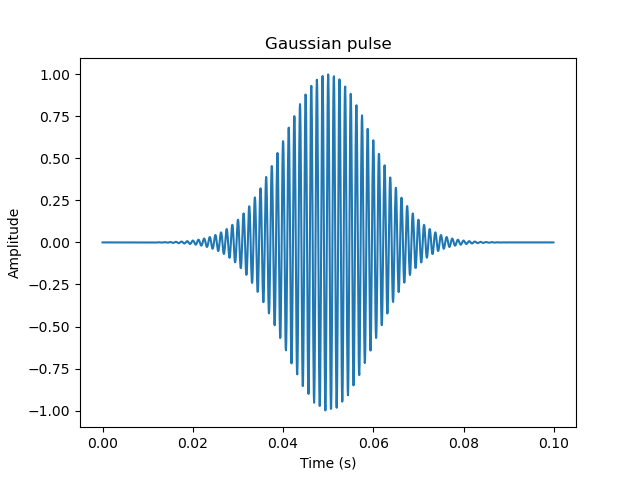

In [6]:
factor = 2.0
fc = 400.0 * factor
T = 40 / fc * factor
fs = 8192.0 * 2
p0_0 = waveforms.generate_gaussian_pulse(T, fc, fs, sigma=0.01)
p0_1 = p0_0

dt = 1 / fs
t = np.arange(0, T - dt, dt)

fig = plt.figure()
plt.plot(t, p0_0, label="p0")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Gaussian pulse")
plt.show()

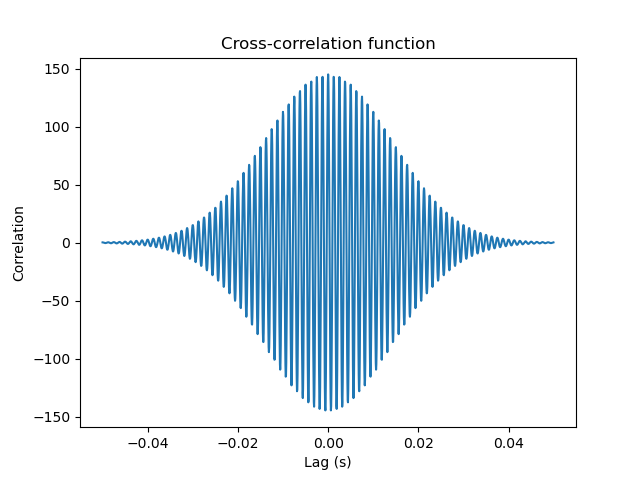

In [5]:
R0xx = signal.correlate(p0_0, p0_0, mode="same")
lags0 = signal.correlation_lags(len(p0_0), len(p0_1), mode="same")
lag_times = lags0 / fs

R0xy = signal.correlate(p0_0, p0_1, mode="same")

plt.figure()
plt.plot(lag_times, R0xx)
plt.xlabel("Lag (s)")
plt.ylabel("Correlation")
plt.title("Cross-correlation function")
plt.show()